In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("log_perso_2025-05-28.csv", names=['url', '#commits', '#files', 'time'])
df_signi = df[df['#commits']>0]
df_signi

,url,#commits,#files,time
3,https://github.com/formulahendry/955.WLB,150,10,0.642484
14,https://github.com/xingshaocheng/architect-awe...,424,9,0.437480
16,https://github.com/GorvGoyl/Clone-Wars,599,40,0.553197
17,https://github.com/2noise/ChatTTS,1022,256,0.364760
21,https://github.com/denysdovhan/wtfjs,937,67,0.154760
...,...,...,...,...
912,https://github.com/sveltejs/svelte,42509,37436,948.411713
913,https://github.com/coolsnowwolf/lede,26301,70740,1244.237923
914,https://github.com/curl/curl,64316,14813,531.600511
915,https://github.com/calcom/cal.com,128311,29780,1913.715327


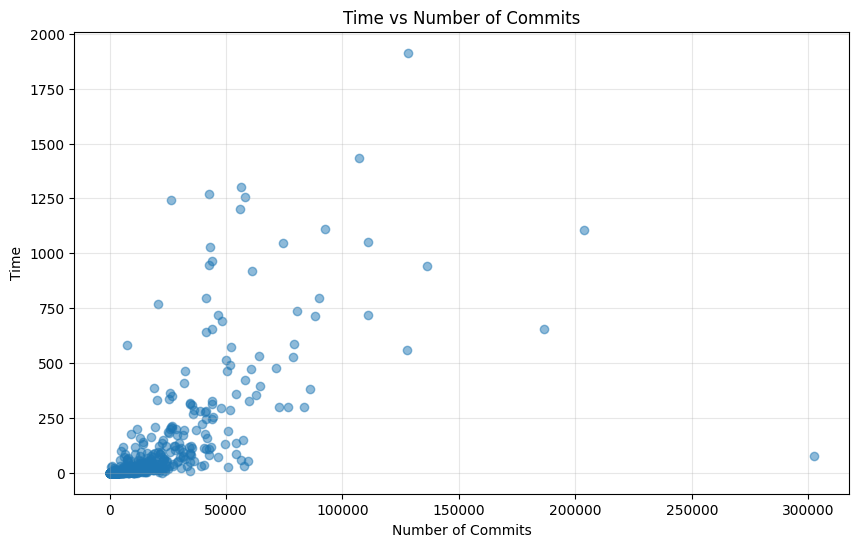

In [4]:
plt.figure(figsize=(10, 6))
plt.scatter(df_signi['#commits'], df_signi['time'], alpha=0.5)
plt.xlabel('Number of Commits')
plt.ylabel('Time')
plt.title('Time vs Number of Commits')
plt.grid(True, alpha=0.3)
plt.show()

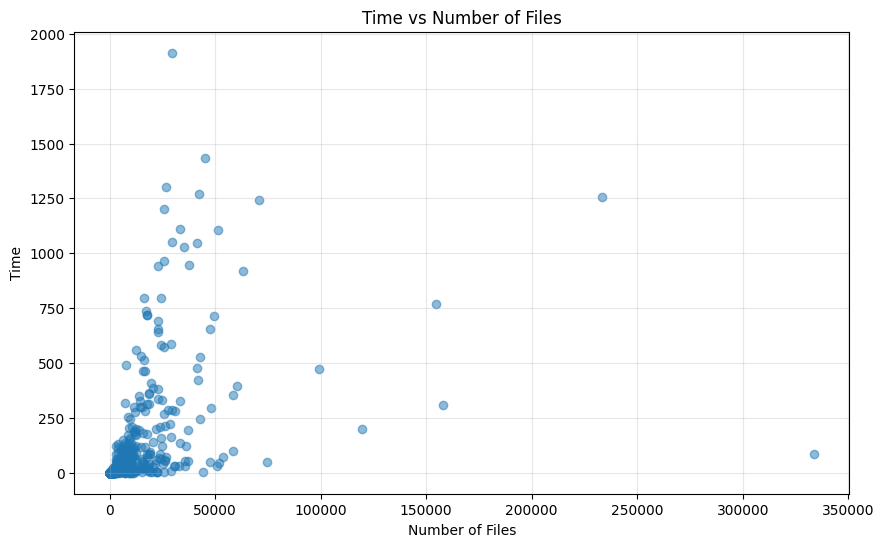

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(df_signi['#files'], df_signi['time'], alpha=0.5)
plt.xlabel('Number of Files')
plt.ylabel('Time')
plt.title('Time vs Number of Files')
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings('ignore')

# Remove any rows with missing values
df_clean = df_signi.dropna()

# Prepare data for commits
X_commits = df_clean['#commits'].values.reshape(-1, 1)
X_files = df_clean['#files'].values.reshape(-1, 1)
y = df_clean['time'].values

# Filter out zeros for log transformations
mask_commits = (df_clean['#commits'] > 0) & (df_clean['time'] > 0)
mask_files = (df_clean['#files'] > 0) & (df_clean['time'] > 0)

def fit_models(X, y, mask, name):
    """Fit different regression models and return R² scores"""
    results = {}
    
    # Linear
    lr = LinearRegression()
    lr.fit(X, y)
    y_pred = lr.predict(X)
    results['Linear'] = r2_score(y, y_pred)
    
    # Polynomial (degree 2)
    poly2 = PolynomialFeatures(degree=2)
    X_poly2 = poly2.fit_transform(X)
    lr2 = LinearRegression()
    lr2.fit(X_poly2, y)
    y_pred2 = lr2.predict(X_poly2)
    results['Polynomial (deg 2)'] = r2_score(y, y_pred2)
    
    # Polynomial (degree 3)
    poly3 = PolynomialFeatures(degree=3)
    X_poly3 = poly3.fit_transform(X)
    lr3 = LinearRegression()
    lr3.fit(X_poly3, y)
    y_pred3 = lr3.predict(X_poly3)
    results['Polynomial (deg 3)'] = r2_score(y, y_pred3)
    
    # Logarithmic (log(x) vs y)
    X_log = np.log(X[mask] + 1).reshape(-1, 1)
    y_log = y[mask]
    lr_log = LinearRegression()
    lr_log.fit(X_log, y_log)
    y_pred_log = lr_log.predict(X_log)
    results['Logarithmic'] = r2_score(y_log, y_pred_log)
    
    # Power law (log(x) vs log(y))
    X_log_power = np.log(X[mask] + 1).reshape(-1, 1)
    y_log_power = np.log(y[mask] + 1)
    lr_power = LinearRegression()
    lr_power.fit(X_log_power, y_log_power)
    y_pred_power = lr_power.predict(X_log_power)
    results['Power Law'] = r2_score(y_log_power, y_pred_power)
    
    print(f"\n{name} - R² scores:")
    print("-" * 40)
    for model, score in sorted(results.items(), key=lambda x: x[1], reverse=True):
        print(f"{model:20s}: {score:.4f}")
    
    return results

# Fit models for both relationships
commits_results = fit_models(X_commits, y, mask_commits, "TIME vs #COMMITS")
files_results = fit_models(X_files, y, mask_files, "TIME vs #FILES")


TIME vs #COMMITS - R² scores:
----------------------------------------
Power Law           : 0.6863
Polynomial (deg 3)  : 0.6014
Polynomial (deg 2)  : 0.5683
Linear              : 0.4647
Logarithmic         : 0.2559

TIME vs #FILES - R² scores:
----------------------------------------
Power Law           : 0.6407
Polynomial (deg 3)  : 0.4024
Polynomial (deg 2)  : 0.3929
Linear              : 0.2222
Logarithmic         : 0.2013


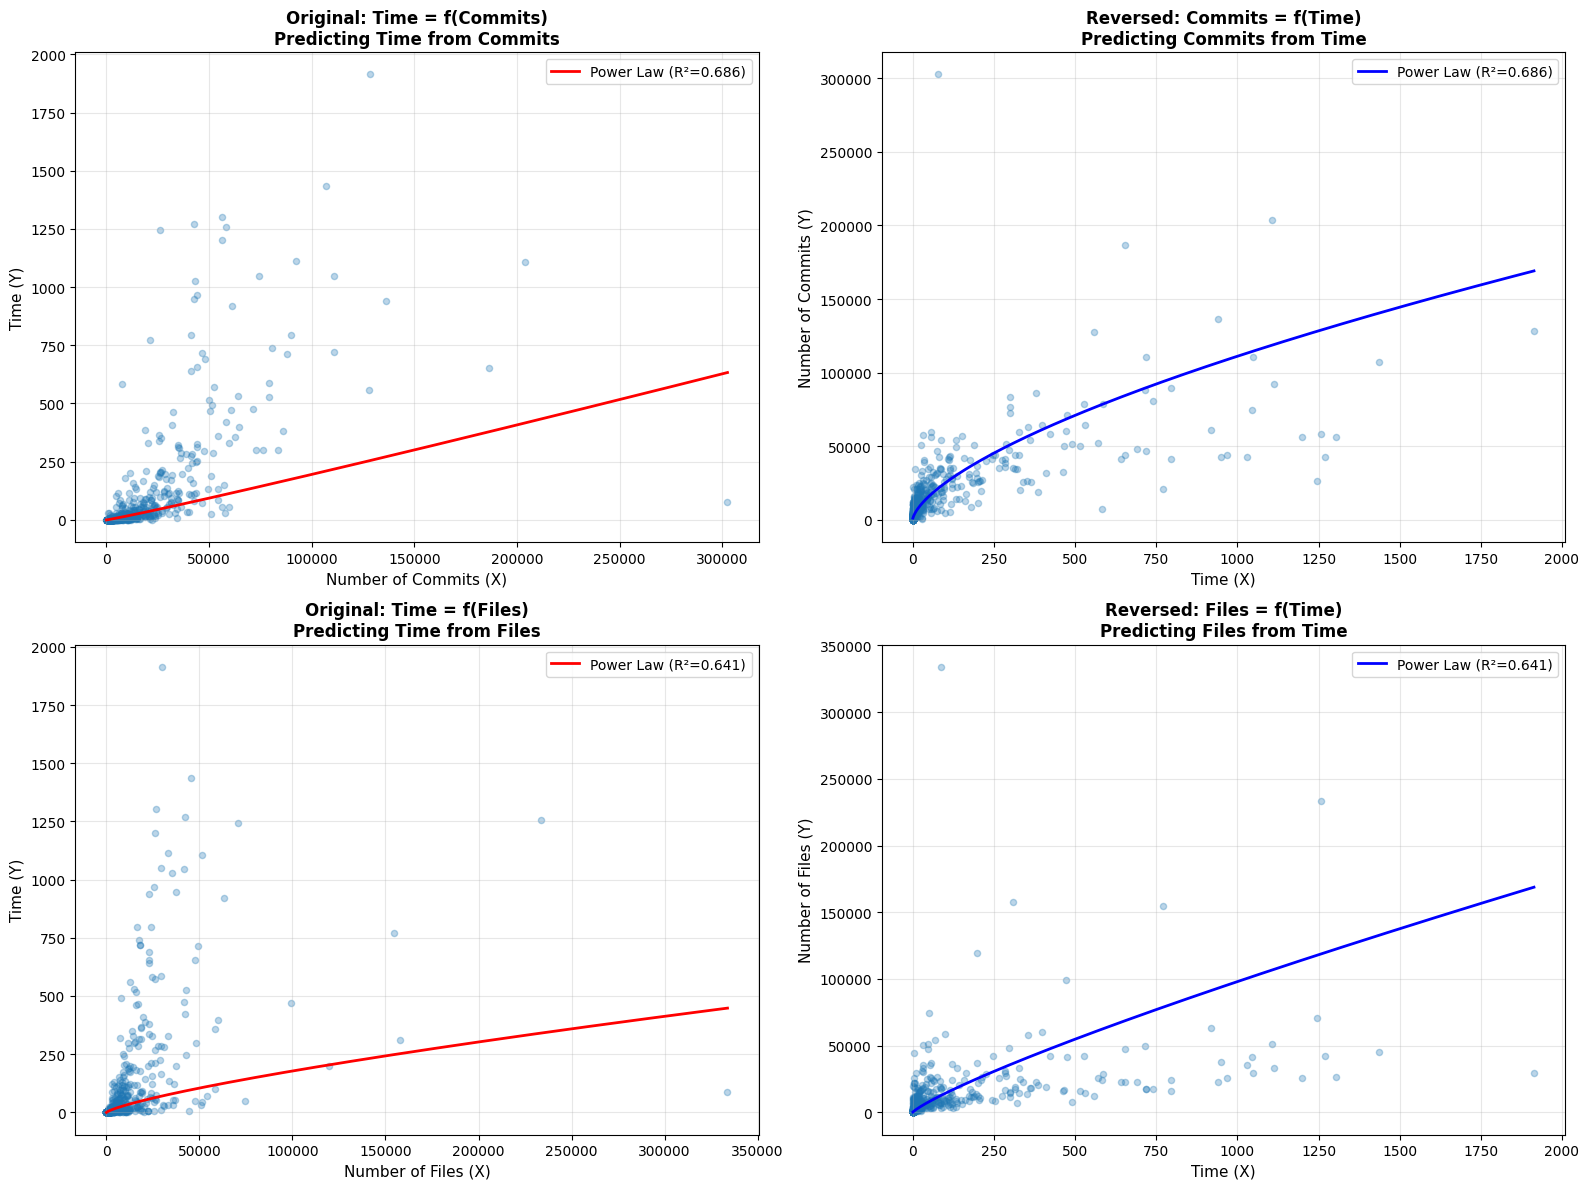


Comparison of Regression Directions:

COMMITS:
  Time = f(Commits):   R² = 0.6863
  Commits = f(Time):   R² = 0.6863

FILES:
  Time = f(Files):     R² = 0.6407
  Files = f(Time):     R² = 0.6407

POWER LAW EQUATIONS:

Original Direction (predicting Time):
  Time vs #Commits: Time ≈ 0.0009644276986124021 x (#Commits)^1.061
  Time vs #Files:   Time ≈ 0.02658130998370171 x (#Files)^0.765

Reversed Direction (predicting Size):
  #Commits vs Time: #Commits ≈ 1276.60 x (Time)^0.647
  #Files vs Time:   #Files ≈ 301.53 x (Time)^0.837


In [8]:
# Compare both regression directions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# === TIME vs #COMMITS ===
# Original: predicting Time from Commits
ax1 = axes[0, 0]
ax1.scatter(df_clean['#commits'], df_clean['time'], alpha=0.3, s=20)
X_log_c = np.log(X_commits[mask_commits] + 1)
y_log_c = np.log(y[mask_commits] + 1)
lr_c = LinearRegression()
lr_c.fit(X_log_c, y_log_c)
X_range_c = np.linspace(X_commits.min(), X_commits.max(), 1000).reshape(-1, 1)
y_pred_c = np.exp(lr_c.predict(np.log(X_range_c + 1))) - 1
ax1.plot(X_range_c, y_pred_c, 'r-', linewidth=2, label=f'Power Law (R²={r2_score(y_log_c, lr_c.predict(X_log_c)):.3f})')
ax1.set_xlabel('Number of Commits (X)', fontsize=11)
ax1.set_ylabel('Time (Y)', fontsize=11)
ax1.set_title('Original: Time = f(Commits)\nPredicting Time from Commits', fontsize=12, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend()

# Reversed: predicting Commits from Time
ax2 = axes[0, 1]
ax2.scatter(df_clean['time'], df_clean['#commits'], alpha=0.3, s=20)
lr_c_rev = LinearRegression()
lr_c_rev.fit(y_log_c.reshape(-1, 1), X_log_c.ravel())
y_range = np.linspace(y.min(), y.max(), 1000).reshape(-1, 1)
mask_y = y_range > 0
x_pred_c = np.exp(lr_c_rev.predict(np.log(y_range[mask_y.ravel()] + 1))) - 1
ax2.plot(y_range[mask_y.ravel()], x_pred_c, 'b-', linewidth=2, label=f'Power Law (R²={r2_score(X_log_c.ravel(), lr_c_rev.predict(y_log_c.reshape(-1, 1))):.3f})')
ax2.set_xlabel('Time (X)', fontsize=11)
ax2.set_ylabel('Number of Commits (Y)', fontsize=11)
ax2.set_title('Reversed: Commits = f(Time)\nPredicting Commits from Time', fontsize=12, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend()

# === TIME vs #FILES ===
# Original: predicting Time from Files
ax3 = axes[1, 0]
ax3.scatter(df_clean['#files'], df_clean['time'], alpha=0.3, s=20)
X_log_f = np.log(X_files[mask_files] + 1)
y_log_f = np.log(y[mask_files] + 1)
lr_f = LinearRegression()
lr_f.fit(X_log_f, y_log_f)
X_range_f = np.linspace(X_files.min(), X_files.max(), 1000).reshape(-1, 1)
y_pred_f = np.exp(lr_f.predict(np.log(X_range_f + 1))) - 1
ax3.plot(X_range_f, y_pred_f, 'r-', linewidth=2, label=f'Power Law (R²={r2_score(y_log_f, lr_f.predict(X_log_f)):.3f})')
ax3.set_xlabel('Number of Files (X)', fontsize=11)
ax3.set_ylabel('Time (Y)', fontsize=11)
ax3.set_title('Original: Time = f(Files)\nPredicting Time from Files', fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.legend()

# Reversed: predicting Files from Time
ax4 = axes[1, 1]
ax4.scatter(df_clean['time'], df_clean['#files'], alpha=0.3, s=20)
lr_f_rev = LinearRegression()
lr_f_rev.fit(y_log_f.reshape(-1, 1), X_log_f.ravel())
x_pred_f = np.exp(lr_f_rev.predict(np.log(y_range[mask_y.ravel()] + 1))) - 1
ax4.plot(y_range[mask_y.ravel()], x_pred_f, 'b-', linewidth=2, label=f'Power Law (R²={r2_score(X_log_f.ravel(), lr_f_rev.predict(y_log_f.reshape(-1, 1))):.3f})')
ax4.set_xlabel('Time (X)', fontsize=11)
ax4.set_ylabel('Number of Files (Y)', fontsize=11)
ax4.set_title('Reversed: Files = f(Time)\nPredicting Files from Time', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)
ax4.legend()

plt.tight_layout()
plt.show()

print("\nComparison of Regression Directions:")
print("="*60)
print("\nCOMMITS:")
print(f"  Time = f(Commits):   R² = {r2_score(y_log_c, lr_c.predict(X_log_c)):.4f}")
print(f"  Commits = f(Time):   R² = {r2_score(X_log_c.ravel(), lr_c_rev.predict(y_log_c.reshape(-1, 1))):.4f}")
print("\nFILES:")
print(f"  Time = f(Files):     R² = {r2_score(y_log_f, lr_f.predict(X_log_f)):.4f}")
print(f"  Files = f(Time):     R² = {r2_score(X_log_f.ravel(), lr_f_rev.predict(y_log_f.reshape(-1, 1))):.4f}")

print("\n" + "="*60)
print("POWER LAW EQUATIONS:")
print("="*60)
print("\nOriginal Direction (predicting Time):")
print(f"  Time vs #Commits: Time ≈ {np.exp(lr_c.intercept_)} x (#Commits)^{lr_c.coef_[0]:.3f}")
print(f"  Time vs #Files:   Time ≈ {np.exp(lr_f.intercept_)} x (#Files)^{lr_f.coef_[0]:.3f}")

print("\nReversed Direction (predicting Size):")
print(f"  #Commits vs Time: #Commits ≈ {np.exp(lr_c_rev.intercept_):.2f} x (Time)^{lr_c_rev.coef_[0]:.3f}")
print(f"  #Files vs Time:   #Files ≈ {np.exp(lr_f_rev.intercept_):.2f} x (Time)^{lr_f_rev.coef_[0]:.3f}")